# Text similarity

## Textual similarity

### Jaccard similarity
#### Data preparation

Read a dataset I prepared (please do not distribute). It has already been tokenized.
Each row contains a pair of two news articles from two local news outlets.


In [8]:
import pandas as pd
from matplotlib.font_manager import font_scalings
from numpy.ma.core import product
from itertools import product
import numpy as np
from tqdm import tqdm
import matplotlib as mlp
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import ast
from sentence_transformers import SentenceTransformer, util
import ssl
import nltk

use_cols = [
    'index_wuva', 'Title_wuva', 'Date Published_wuva', 'Description_wuva',
    'index_wvtm', 'Title_wvtm', 'Date Published_wvtm', 'Description_wvtm',
    'wuva_tokens', 'wvtm_tokens']

news_pairs = pd.read_csv("./data/news_pairs.csv", usecols=use_cols)

# the following step is essential because csv does not save list as Python obeject. Instead, it saves as a string. so we need to cast it back to a list (Python object)
list_cols = ['wuva_tokens', 'wvtm_tokens']
for col in list_cols:
    news_pairs[col] = news_pairs[col].apply(ast.literal_eval)

print("data prepared")


data prepared


In [9]:
news_pairs.head()

,index_wuva,Title_wuva,Date Published_wuva,Description_wuva,index_wvtm,Title_wvtm,Date Published_wvtm,Description_wvtm,wuva_tokens,wvtm_tokens
0,338,Alabama senior seeks out new challenges in pat...,2024-06-24,By WVUA 23 Digital Reporter Candace Johnson Ri...,52818,12 new UAB construction and renovation project...,2024-06-25,There are currently12 new construction project...,"[alabama, senior, seek, new, challenge, path, ...","[12, new, uab, construction, renovation, proje..."
1,341,12 University of Alabama students are vying fo...,2024-06-24,Twelve students who attend the University of ...,52818,12 new UAB construction and renovation project...,2024-06-25,There are currently12 new construction project...,"[12, university, alabama, student, vie, miss, ...","[12, new, uab, construction, renovation, proje..."
2,350,Look before you lock: Don't leave children in ...,2024-06-21,By WVUA 23 News Reporter Zoe Blair The temper...,52816,Doctors urging people to stay hydrated during ...,2024-06-14,Doctors withAmerican Family Careare urging peo...,"[look, lock, leave, child, hot, car, wvua, 23,...","[doctor, urge, people, stay, hydrate, dangerou..."
3,359,Alabama seeking foster care homes for older ad...,2024-06-21,By WVUA 23 Digital Reporter Candace Johnson Ju...,52816,Doctors urging people to stay hydrated during ...,2024-06-14,Doctors withAmerican Family Careare urging peo...,"[alabama, seek, foster, care, home, old, adult...","[doctor, urge, people, stay, hydrate, dangerou..."
4,401,Children's of Alabama celebrates 113th birthda...,2024-06-18,By WVUA 23 Digital Reporter Candace Johnson Ch...,52816,Doctors urging people to stay hydrated during ...,2024-06-14,Doctors withAmerican Family Careare urging peo...,"[child, alabama, celebrate, 113th, birthday, w...","[doctor, urge, people, stay, hydrate, dangerou..."


#### Compute token Jaccard similarity

In [10]:
# Jaccard similarity of tokens.
def jaccard_from_lists(tokens1, tokens2):
    if not isinstance(tokens1, list) or not isinstance(tokens2, list):
        return 0

    set1 = set(tokens1)
    set2 = set(tokens2)

    union = set1 | set2
    if len(union) == 0:
        return 0

    return len(set1 & set2) / len(union)

news_pairs["tokenized_jaccard_similarity"] = news_pairs.apply(
    lambda row: jaccard_from_lists(row["wuva_tokens"], row["wvtm_tokens"]),
    axis=1)


In [11]:
news_pairs.head()

,index_wuva,Title_wuva,Date Published_wuva,Description_wuva,index_wvtm,Title_wvtm,Date Published_wvtm,Description_wvtm,wuva_tokens,wvtm_tokens,tokenized_jaccard_similarity
0,338,Alabama senior seeks out new challenges in pat...,2024-06-24,By WVUA 23 Digital Reporter Candace Johnson Ri...,52818,12 new UAB construction and renovation project...,2024-06-25,There are currently12 new construction project...,"[alabama, senior, seek, new, challenge, path, ...","[12, new, uab, construction, renovation, proje...",0.052288
1,341,12 University of Alabama students are vying fo...,2024-06-24,Twelve students who attend the University of ...,52818,12 new UAB construction and renovation project...,2024-06-25,There are currently12 new construction project...,"[12, university, alabama, student, vie, miss, ...","[12, new, uab, construction, renovation, proje...",0.031746
2,350,Look before you lock: Don't leave children in ...,2024-06-21,By WVUA 23 News Reporter Zoe Blair The temper...,52816,Doctors urging people to stay hydrated during ...,2024-06-14,Doctors withAmerican Family Careare urging peo...,"[look, lock, leave, child, hot, car, wvua, 23,...","[doctor, urge, people, stay, hydrate, dangerou...",0.092308
3,359,Alabama seeking foster care homes for older ad...,2024-06-21,By WVUA 23 Digital Reporter Candace Johnson Ju...,52816,Doctors urging people to stay hydrated during ...,2024-06-14,Doctors withAmerican Family Careare urging peo...,"[alabama, seek, foster, care, home, old, adult...","[doctor, urge, people, stay, hydrate, dangerou...",0.060150
4,401,Children's of Alabama celebrates 113th birthda...,2024-06-18,By WVUA 23 Digital Reporter Candace Johnson Ch...,52816,Doctors urging people to stay hydrated during ...,2024-06-14,Doctors withAmerican Family Careare urging peo...,"[child, alabama, celebrate, 113th, birthday, w...","[doctor, urge, people, stay, hydrate, dangerou...",0.038251


<Axes: xlabel='tokenized_jaccard_similarity', ylabel='Count'>

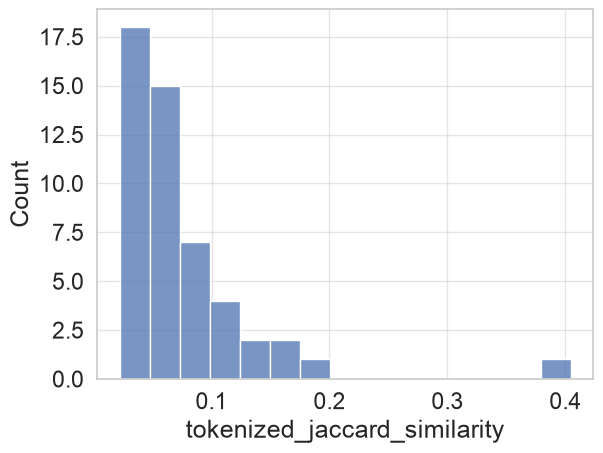

In [16]:

sns.set_theme(style="whitegrid", font_scale=1.5)

sns.histplot(data=news_pairs, x="tokenized_jaccard_similarity")


### bigram overlap (similarity)

In [18]:
from nltk.util import ngrams

# generate bigram first
news_pairs["wuva_bigrams"] = news_pairs["wuva_tokens"].apply(
    lambda tokens: list(ngrams(tokens, 2)))

news_pairs["wvtm_bigrams"] = news_pairs["wvtm_tokens"].apply(
    lambda tokens: list(ngrams(tokens, 2)))

In [19]:
news_pairs["bigram_jaccard_similarity"] = news_pairs.apply(
    lambda row: jaccard_from_lists(row["wuva_bigrams"], row["wvtm_bigrams"]),
    axis=1)

<Axes: xlabel='bigram_jaccard_similarity', ylabel='Count'>

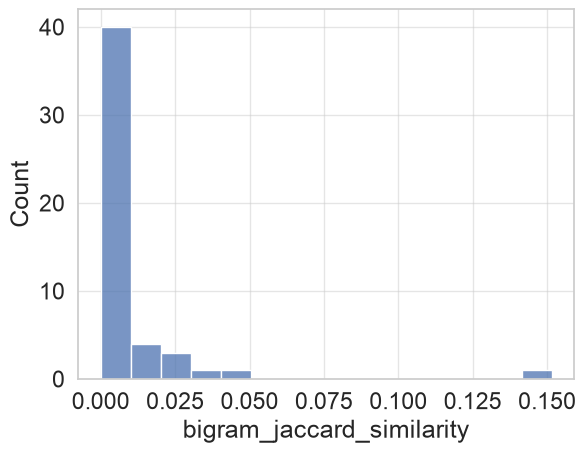

In [22]:

sns.set_theme(style="whitegrid", font_scale=1.5)
sns.histplot(data=news_pairs, x="bigram_jaccard_similarity")


<Axes: xlabel='tokenized_jaccard_similarity', ylabel='bigram_jaccard_similarity'>

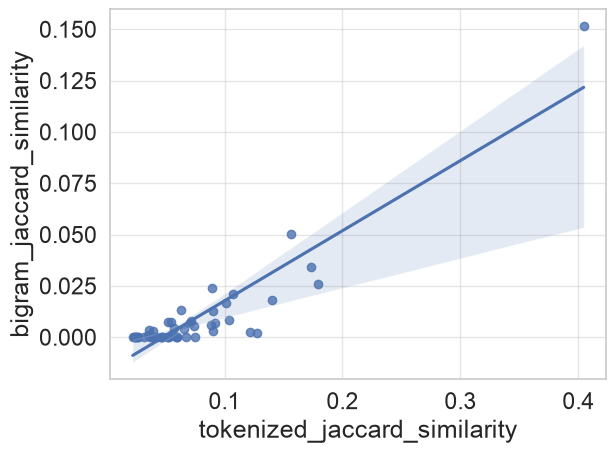

In [24]:
sns.regplot(data=news_pairs, x='tokenized_jaccard_similarity', y="bigram_jaccard_similarity")

### TF-IDF cosine similarity

TF-IDF cosine similarity measures how similar two documents are based on the words they use, while giving greater importance to words that are relatively distinctive across a collection of documents.

It combines two concepts: TF-IDF, which determines the importance of each word, and cosine similarity, which compares two documents based on those weighted words.

In [25]:
# compute TF-IDF cosine similarity
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

news_pairs["wuva_text"] = news_pairs["wuva_tokens"].apply(lambda toks: " ".join(toks) if isinstance(toks, list) else "")
news_pairs["wvtm_text"] = news_pairs["wvtm_tokens"].apply(lambda toks: " ".join(toks) if isinstance(toks, list) else "")

corpus = pd.concat([news_pairs["wuva_text"], news_pairs["wvtm_text"]]).fillna("")

vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(corpus)

N = len(news_pairs)
wuva_tfidf = tfidf_matrix[:N]
wvtm_tfidf = tfidf_matrix[N:]

cosine_scores = [
    cosine_similarity(wuva_tfidf[i], wvtm_tfidf[i])[0, 0]
    for i in range(N)
]

news_pairs["tfidf_cosine"] = cosine_scores
print("TF-IDF cosine similarity computed")

TF-IDF cosine similarity computed


In [26]:
news_pairs['tfidf_cosine'].describe()

count    50.000000
mean      0.115035
std       0.142289
min       0.004500
25%       0.023944
50%       0.057140
75%       0.139082
max       0.700371
Name: tfidf_cosine, dtype: float64

<Axes: xlabel='tfidf_cosine', ylabel='Count'>

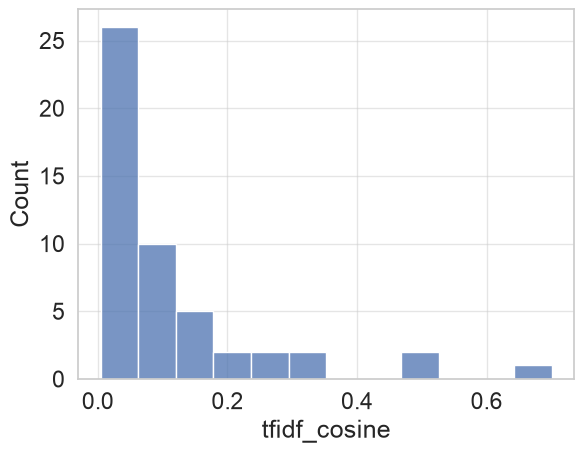

In [28]:
sns.histplot(data=news_pairs, x="tfidf_cosine")

<Axes: xlabel='tokenized_jaccard_similarity', ylabel='tfidf_cosine'>

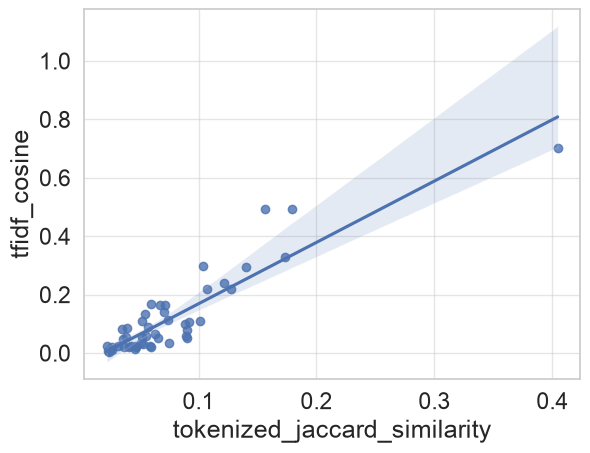

In [30]:
sns.regplot(data=news_pairs, x="tokenized_jaccard_similarity", y="tfidf_cosine")

## Semantic similarity

Let's compute semantic similarity between pairs of news articles using a pretrained Sentence Transformer model (all-MiniLM-L6-v2).

Unlike lexical similarity measures such as Jaccard or TF-IDF cosine similarity, which rely on shared words, semantic similarity captures similarities in meaning even when different words or expressions are used.

The model converts each news article into a numerical vector called an embedding, which represents its semantic content. We then calculate cosine similarity between the embeddings of each matched pair of articles. Because the embeddings are normalized, cosine similarity can be calculated directly using their dot product. Higher scores indicate greater similarity in meaning, while lower scores indicate less similarity.

In [31]:
# compute semantic similarity using sentence transfoemer

model = SentenceTransformer("all-MiniLM-L6-v2")

wuva_embeddings = model.encode(
    news_pairs["wuva_text"].tolist(),
    convert_to_tensor=True,
    normalize_embeddings=True)

wvtm_embeddings = model.encode(
    news_pairs["wvtm_text"].tolist(),
    convert_to_tensor=True,
    normalize_embeddings=True)

# Because we normalized, cosine similarity is just dot product row-wise
semantic_scores = (wuva_embeddings * wvtm_embeddings).sum(dim=1)

# Move to CPU + numpy, then assign to dataframe
news_pairs["semantic_similarity"] = semantic_scores.cpu().numpy()

print("meaning based sentence similarity computed")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

meaning based sentence similarity computed


<Axes: xlabel='semantic_similarity', ylabel='Count'>

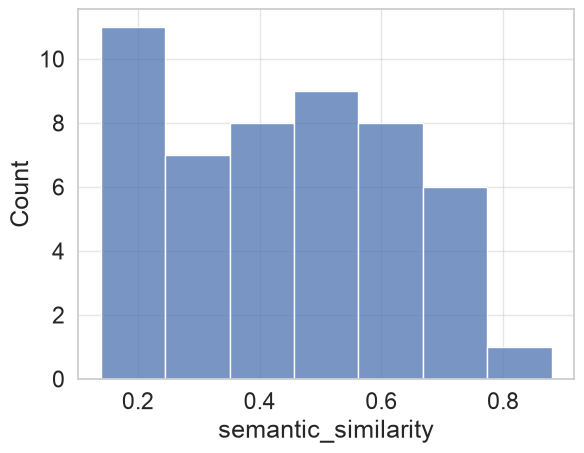

In [32]:
sns.histplot(data=news_pairs, x="semantic_similarity")

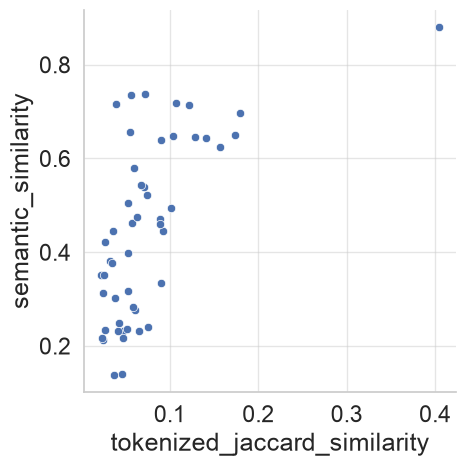

In [33]:
sns.relplot(data=news_pairs, x="tokenized_jaccard_similarity", y="semantic_similarity")

In [34]:
news_pairs.columns

Index(['index_wuva', 'Title_wuva', 'Date Published_wuva', 'Description_wuva',
       'index_wvtm', 'Title_wvtm', 'Date Published_wvtm', 'Description_wvtm',
       'wuva_tokens', 'wvtm_tokens', 'tokenized_jaccard_similarity',
       'wuva_bigrams', 'wvtm_bigrams', 'bigram_jaccard_similarity',
       'wuva_text', 'wvtm_text', 'tfidf_cosine', 'semantic_similarity'],
      dtype='str')

## Inspect

In [36]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
import html
import pandas as pd

# 1. Similarity measure dropdown
similarity_dropdown = widgets.Dropdown(
    options=[
        ("Bigram Jaccard Similarity", "bigram_jaccard_similarity"),
        ("TF-IDF Cosine Similarity", "tfidf_cosine"),
        ("Semantic Similarity", "semantic_similarity")
    ],
    value="semantic_similarity",
    description="Similarity Measure:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="400px")
)

# 2. Similarity range selector
similarity_slider = widgets.FloatRangeSlider(
    value=[0.5, 0.8],
    min=0.0,
    max=1.0,
    step=0.05,
    description="Similarity Range:",
    continuous_update=False,
    readout_format=".2f",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="550px")
)

# 3. Random sample button
sample_button = widgets.Button(
    description="Randomly Select Another Pair",
    button_style="info",
    icon="random",
    layout=widgets.Layout(width="260px")
)

# 4. Output area
output = widgets.Output()

def display_random_pair(_=None):
    with output:
        clear_output(wait=True)

        # Get selected similarity measure and range
        similarity_col = similarity_dropdown.value
        lower, upper = similarity_slider.value

        # Filter matched pairs
        filtered = news_pairs[
            news_pairs[similarity_col].between(lower, upper)
        ]

        if filtered.empty:
            display(HTML(
                "<p style='color:red;'>"
                "No matched pairs found in this similarity range."
                "</p>"
            ))
            return

        # Randomly select one matched pair
        pair = filtered.sample(n=1).iloc[0]

        # Format text safely
        def format_value(value):
            if pd.isna(value):
                return "N/A"
            return html.escape(str(value)).replace("\n", "<br>")

        # Format similarity scores
        def format_score(column):
            value = pair[column]
            return f"{value:.3f}" if pd.notna(value) else "N/A"

        # Article card
        def article_card(source, title, date, description, article_id=None):

            id_text = (
                f"<p><strong>Article ID:</strong> {format_value(article_id)}</p>"
                if article_id is not None else ""
            )

            return f"""
            <div style="
                flex: 1;
                min-width: 0;
                padding: 18px;
                border: 1px solid #ccc;
                border-radius: 8px;
                background-color: #fafafa;
                color: #222;
                overflow-wrap: anywhere;
            ">
                <h3 style="margin-top:0;">{source}</h3>
                {id_text}
                <h4>{format_value(title)}</h4>
                <p><strong>Date Published:</strong> {format_value(date)}</p>
                <hr>
                <p style="line-height:1.6;">
                    {format_value(description)}
                </p>
            </div>
            """

        wuva_html = article_card(
            "WVUA",
            pair["Title_wuva"],
            pair["Date Published_wuva"],
            pair["Description_wuva"],
            pair["index_wuva"]
        )

        wvtm_html = article_card(
            "WVTM",
            pair["Title_wvtm"],
            pair["Date Published_wvtm"],
            pair["Description_wvtm"],
            pair["index_wvtm"]
        )

        # Display comparison
        display(HTML(f"""
            <h3>Selected Similarity Measure: {similarity_dropdown.label}</h3>

            <p>
                Matched pairs in selected range:
                <strong>{len(filtered):,}</strong>
            </p>

            <div style="
                display:flex;
                gap:20px;
                margin-bottom:20px;
            ">
                <div style="flex:1;">
                    <strong>Bigram Jaccard:</strong>
                    {format_score("bigram_jaccard_similarity")}
                </div>
                <div style="flex:1;">
                    <strong>TF-IDF Cosine:</strong>
                    {format_score("tfidf_cosine")}
                </div>
                <div style="flex:1;">
                    <strong>Semantic Similarity:</strong>
                    {format_score("semantic_similarity")}
                </div>
            </div>

            <div style="
                display:flex;
                gap:20px;
                align-items:stretch;
                width:100%;
            ">
                {wuva_html}
                {wvtm_html}
            </div>
        """))


# 5. Connect widget interactions
sample_button.on_click(display_random_pair)

similarity_slider.observe(
    display_random_pair,
    names="value"
)

similarity_dropdown.observe(
    display_random_pair,
    names="value"
)

# 6. Display widget
display(widgets.VBox([
    similarity_dropdown,
    similarity_slider,
    sample_button,
    output
]))

# Show an initial random pair
display_random_pair()